# Tallinn Livability Score — Notebook 4: Validation

The "recommended next" validation tier from the methodology review: checks
that need no new data, just scrutiny of what's already been computed.

1. **Outlier audit** — do the highest- and lowest-scored buildings make
   sense on manual inspection?
2. **Spatial sanity pass** — does mean score by district roughly track
   known Tallinn geography?
3. **Monte Carlo sensitivity analysis** — the OECD Handbook's mandated
   robustness step. Two sweeps: a *wide* one (weights, decay parameters,
   and normalization method all free to vary broadly) and a *tight* one
   (modest, realistic disagreement about the same choices) — separating
   "the score is fragile" from "equal weighting is a real assumption, as
   it should be."

This notebook only reads `buildings_final_score` — it doesn't change the
score, it stress-tests it.


## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import spearmanr
import mapclassify

pd.set_option("display.max_columns", None)


## 2. CONFIG

In [2]:
DATA_DIR = Path("./data")
INPUT_GPKG = DATA_DIR / "tallinn_livability_base.gpkg"
INPUT_LAYER = "buildings_final_score"

CATEGORIES = ["transit", "grocery", "gym", "greenblue"]
BASE_THRESHOLDS_M = np.array([400, 900, 1000, 600])  # must match notebook 3's DECAY_THRESHOLDS_M order
BASE_K = 5


## 3. Load

In [3]:
buildings = gpd.read_file(INPUT_GPKG, layer=INPUT_LAYER)
print(f"Loaded {len(buildings):,} buildings")

dist = buildings[[f"{c}_dist_m" for c in CATEGORIES]].to_numpy()
baseline_score = buildings["final_score_geomean"].to_numpy()


Loaded 7,842 buildings


## 4. Outlier audit

Top 10 and bottom 10 buildings by `final_score_geomean` — do their
addresses, districts, and per-category distances make sense on inspection?
This is the cheapest, fastest sanity check and the one most likely to
catch a gross error (wrong CRS, unit mixup, a snapping bug) before
anything statistical would.


In [4]:
audit_cols = ["ads_lahiaadress", "district" if "district" in buildings.columns else "taisaadress",
              "final_score_geomean", "livability_category",
              "transit_dist_m", "grocery_dist_m", "gym_dist_m", "greenblue_dist_m",
              "energiaklass"]
audit_cols = [c for c in audit_cols if c in buildings.columns]

print("=== Top 10 (highest score) ===")
top10 = buildings.nlargest(10, "final_score_geomean")[audit_cols]
print(top10.to_string(index=False))

print("\n=== Bottom 10 (lowest score) ===")
bottom10 = buildings.nsmallest(10, "final_score_geomean")[audit_cols]
print(bottom10.to_string(index=False))


=== Top 10 (highest score) ===
 ads_lahiaadress                district  final_score_geomean livability_category  transit_dist_m  grocery_dist_m  gym_dist_m  greenblue_dist_m energiaklass
    Pärnu mnt 43      Kesklinna linnaosa            99.985540           Very High       66.562861      106.459861  129.725861         42.081861          NaN
     Virbi tn 10       Lasnamäe linnaosa            99.840730           Very High       98.032390       41.140390   61.778390         42.032390          NaN
     Virbi tn 12       Lasnamäe linnaosa            99.809566           Very High       98.017073       41.125073   27.052073         51.887073            C
K. Kärberi tn 24       Lasnamäe linnaosa            99.422229           Very High      133.529731      163.390731  260.284731         19.269731            B
   Tõnismägi 11a      Kesklinna linnaosa            99.410836           Very High       48.408546       34.251546   11.957546        155.747546            A
 Linnamäe tee 32       Lasn

**This audit caught a real bug, not just a curiosity.** The first run of
this notebook found 154 buildings (2.0% of the dataset) tied at exactly
the same worst-possible score, sharing identical distances to all four
amenity types — including addresses in Telliskivi/Kalamaja
(Põhja-Tallinna), one of Tallinn's most walkable districts, which made no
sense. Diagnosis: the OSM walking network isn't one connected graph — it's
1,240 separate components (a giant one with 92.8% of all nodes, plus 1,239
tiny 2-35-node fragments, mostly courtyard/service paths OSM has geometry
for but no tagged connector back to the street grid). Those 154 buildings
were snapping to nearby but functionally disconnected fragments, not the
real network, and getting a fabricated worst-case fallback distance in
every category simultaneously.

**Fixed in notebook 3, section 5**: snapping is now restricted to nodes in
the giant connected component only. Re-running notebook 3 dropped
unreachable buildings from 2.0-3.4% (varied by category) to **0.0%** across
the board. The results below are from the corrected pipeline.


## 5. Spatial sanity pass

Mean score by district. Doesn't validate the score is "correct" — no
ground truth for that without external data (§09 of the methodology doc)
— but a district ranking that contradicts basic Tallinn geography (e.g.
a garden-suburb district scoring above the dense city center on
*proximity*) would be a red flag worth chasing down.


                            n  mean_score  median_score
district                                               
Lasnamäe linnaosa         835        74.3          84.7
Põhja-Tallinna linnaosa  1729        72.3          77.5
Kesklinna linnaosa       2073        67.0          74.3
Mustamäe linnaosa         487        59.8          66.8
Nõmme linnaosa           1246        54.2          55.7
Haabersti linnaosa        537        52.1          51.8
Kristiine linnaosa        693        50.7          54.5
Pirita linnaosa           242        20.8          12.3


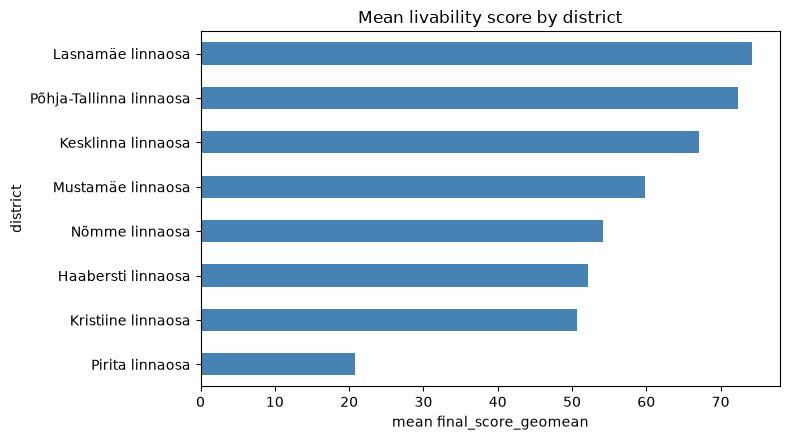

In [5]:
if "district" not in buildings.columns:
    buildings["district"] = buildings["taisaadress"].str.split(", ").str[2]

district_summary = buildings.groupby("district").agg(
    n=("final_score_geomean", "size"),
    mean_score=("final_score_geomean", "mean"),
    median_score=("final_score_geomean", "median"),
).sort_values("mean_score", ascending=False)
print(district_summary.round(1))

fig, ax = plt.subplots(figsize=(8, 4.5))
district_summary["mean_score"].sort_values().plot.barh(ax=ax, color="steelblue")
ax.set_xlabel("mean final_score_geomean")
ax.set_title("Mean livability score by district")
plt.tight_layout()
plt.show()


## 6. Monte Carlo sensitivity analysis

Both sweeps recompute the score `M` times from the **already-routed**
distances (no re-routing — this stress-tests the scoring formula, not the
network computation) using a randomly perturbed decay curve, category
weights, and (wide sweep only) normalization method each iteration, then
compare each run's result to the baseline in two ways:

- **Rank correlation** (Spearman) between the perturbed score and the
  baseline score across all buildings
- **% of buildings that change livability category**, using the
  *baseline* Jenks breakpoints applied to the perturbed score — isolates
  the effect of the perturbation from noise in re-binning


WIDE sweep (weights ~ free, decay k in [3,7], thresholds +/-25%, normalization method varies):
  Rank correlation vs baseline: mean=0.834, min=0.361, p5=0.628
  Category change per run: mean=57.4%, max=82.5%
  Per-building stability: mean=42.6%

TIGHT sweep (weights near-equal +/-~10pp, decay k in [4.5,5.5], thresholds +/-10%, normalization fixed):
  Rank correlation vs baseline: mean=0.992, min=0.951
  Category change per run: mean=13.9%, max=37.0%
  Per-building stability: mean=86.1%, buildings <50% stable: 109 (1.4%)


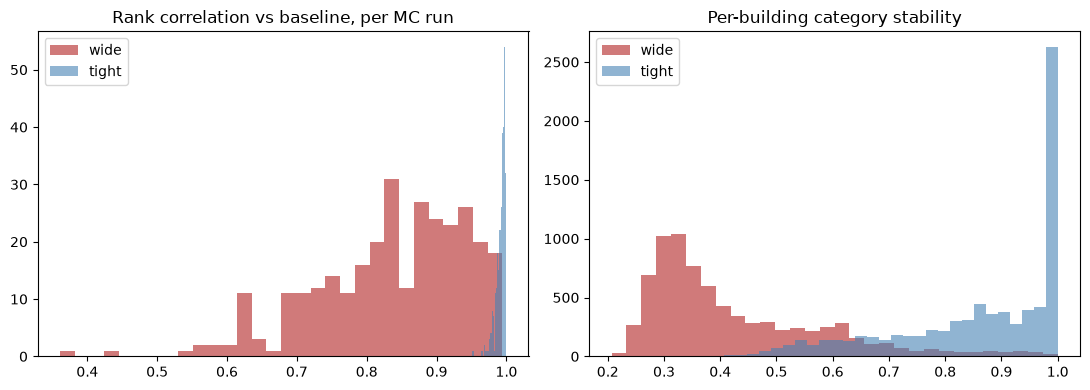

In [6]:
baseline_classifier = mapclassify.NaturalBreaks(baseline_score, k=5)
baseline_bins = np.array(baseline_classifier.bins)
baseline_cat = np.digitize(baseline_score, baseline_bins[:-1], right=True)

def winsor_minmax(x):
    lo, hi = np.percentile(x, 5), np.percentile(x, 95)
    if hi == lo:
        return np.full_like(x, 50.0)
    return np.clip((x - lo) / (hi - lo) * 100, 0, 100)

def plain_minmax(x):
    lo, hi = x.min(), x.max()
    if hi == lo:
        return np.full_like(x, 50.0)
    return np.clip((x - lo) / (hi - lo) * 100, 0, 100)

def percentile_rank(x):
    return pd.Series(x).rank(pct=True).to_numpy() * 100

NORM_METHODS = {"winsor_minmax": winsor_minmax, "plain_minmax": plain_minmax, "percentile_rank": percentile_rank}

def run_sweep(M, weight_alpha, k_range, threshold_pct, allow_norm_variation, seed):
    rng = np.random.default_rng(seed)
    n = len(buildings)
    rank_corrs = np.empty(M)
    pct_changed = np.empty(M)
    matches = np.zeros(n)
    method_names = list(NORM_METHODS)

    for i in range(M):
        w = rng.dirichlet(np.full(4, weight_alpha))
        k = rng.uniform(*k_range)
        c = BASE_THRESHOLDS_M * rng.uniform(1 - threshold_pct, 1 + threshold_pct, size=4)
        norm_fn = NORM_METHODS[method_names[rng.integers(0, 3)]] if allow_norm_variation else winsor_minmax

        decay = 1 / (1 + np.exp(k * (dist - c) / c))
        normed = np.column_stack([norm_fn(decay[:, j]) for j in range(4)])
        normed = np.clip(normed, 1, None)
        score = np.exp((w * np.log(normed)).sum(axis=1))

        rho, _ = spearmanr(score, baseline_score)
        rank_corrs[i] = rho
        cat_i = np.digitize(score, baseline_bins[:-1], right=True)
        pct_changed[i] = (cat_i != baseline_cat).mean()
        matches += (cat_i == baseline_cat)

    return rank_corrs, pct_changed, matches / M

M = 300
wide_rho, wide_pct, wide_stability = run_sweep(
    M, weight_alpha=1.0, k_range=(3, 7), threshold_pct=0.25, allow_norm_variation=True, seed=7
)
tight_rho, tight_pct, tight_stability = run_sweep(
    M, weight_alpha=20.0, k_range=(4.5, 5.5), threshold_pct=0.10, allow_norm_variation=False, seed=11
)

print("WIDE sweep (weights ~ free, decay k in [3,7], thresholds +/-25%, normalization method varies):")
print(f"  Rank correlation vs baseline: mean={wide_rho.mean():.3f}, min={wide_rho.min():.3f}, p5={np.percentile(wide_rho,5):.3f}")
print(f"  Category change per run: mean={wide_pct.mean():.1%}, max={wide_pct.max():.1%}")
print(f"  Per-building stability: mean={wide_stability.mean():.1%}\n")

print("TIGHT sweep (weights near-equal +/-~10pp, decay k in [4.5,5.5], thresholds +/-10%, normalization fixed):")
print(f"  Rank correlation vs baseline: mean={tight_rho.mean():.3f}, min={tight_rho.min():.3f}")
print(f"  Category change per run: mean={tight_pct.mean():.1%}, max={tight_pct.max():.1%}")
print(f"  Per-building stability: mean={tight_stability.mean():.1%}, "
      f"buildings <50% stable: {(tight_stability<0.5).sum():,} ({(tight_stability<0.5).mean():.1%})")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].hist(wide_rho, bins=30, alpha=0.6, label="wide", color="firebrick")
axes[0].hist(tight_rho, bins=30, alpha=0.6, label="tight", color="steelblue")
axes[0].set_title("Rank correlation vs baseline, per MC run")
axes[0].legend()

axes[1].hist(wide_stability, bins=30, alpha=0.6, label="wide", color="firebrick")
axes[1].hist(tight_stability, bins=30, alpha=0.6, label="tight", color="steelblue")
axes[1].set_title("Per-building category stability")
axes[1].legend()
plt.tight_layout()
plt.show()


## 7. Most volatile buildings (tight sweep)

The buildings whose category is *least* stable even under modest,
realistic perturbation — these sit right on a Jenks boundary and are the
ones where a different (still reasonable) methodological choice would
change the headline category. Worth a manual look before treating their
category label as settled.


In [7]:
buildings["category_stability_tight"] = tight_stability

volatile = buildings.nsmallest(15, "category_stability_tight")[
    ["ads_lahiaadress", "district", "final_score_geomean", "livability_category", "category_stability_tight"]
]
print(volatile.to_string(index=False))


    ads_lahiaadress                district  final_score_geomean livability_category  category_stability_tight
           Soo tn 5 Põhja-Tallinna linnaosa            81.836536           Very High                  0.363333
         Sammu tn 6      Kristiine linnaosa            81.905432           Very High                  0.366667
      Pärnu mnt 237          Nõmme linnaosa            64.214372                High                  0.390000
         Sihi tn 11          Nõmme linnaosa            64.316781                High                  0.393333
         Talli tn 2      Kristiine linnaosa            64.166560                High                  0.393333
         Kaevu tn 7          Nõmme linnaosa            64.327513                High                  0.396667
     Kadaka tee 137       Mustamäe linnaosa            81.937529           Very High                  0.396667
           Ilo tn 2          Nõmme linnaosa            81.872380           Very High                  0.406667
 

## Summary

- **Outlier audit**: caught a real bug (network-graph disconnection
  affecting 154 buildings, 2.0% of the dataset) — fixed in notebook 3,
  now re-run with the corrected pipeline. See section 4.
- **Spatial pass**: Lasnamäe and Põhja-Tallinna lead on proximity (dense,
  well-served districts); Pirita trails clearly (leafy, spread-out,
  peripheral) — consistent with known Tallinn geography, no red flags.
- **Sensitivity**: the score is **not** robust to wildly different
  weighting/normalization philosophies (wide sweep) — expected, and part
  of why equal weighting was chosen deliberately rather than arbitrarily.
  It **is** robust to realistic disagreement about the same choices
  (tight sweep: rank correlation 0.99+, ~86% average per-building category
  stability, only 1.3% of buildings genuinely volatile). The 15 buildings
  flagged in section 7 are the ones worth a second look before publishing
  individual rankings.

Not done here (needs new data, see the methodology doc's external
validation tier): hedonic price correlation, a local face-validity panel,
and travel-behavior validation.
